In [1]:
import time
import torch
import numpy as np
from addict import Dict
import matplotlib.pyplot as plt

# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager

# 可视化
from utils.visualizer import plot_events_3d, plot_event_time2d, save_voxel_grid_video, plot_flow_field
from CMax import ContrastMaximizationLoss
from methods import inr_vg,inr_est,of_vg,of_est, ilk_vg, ilk_est, affineGS, constGS, compute_flow_quantities
# 评价指标
from utils.metrics import PIVmetric
from gaussian_flow.config import GaussianFlowConfig
from gaussian_flow.training import run_gaussian_flow


CMax fused extension: OK
Using device: cuda


In [2]:
import gc
import time


def _sync_cuda():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def reset_peak_device_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()


def read_peak_device_memory_mb():
    if not torch.cuda.is_available():
        return None, None
    allocated = torch.cuda.max_memory_allocated() / 1024**2
    reserved = torch.cuda.max_memory_reserved() / 1024**2
    return allocated, reserved


def count_learnable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def count_inr_learnable_params(ne=64, beta=100):
    model = MLP_Conv(ne=ne, beta=beta)
    return count_learnable_params(model)


def gaussian_param_text(model):
    n = model.num_gaussians
    total = count_learnable_params(model)
    per_gaussian = total / n if n > 0 else 0
    return f"{n} x {per_gaussian:.0f} = {total}"


def measure_peak_memory(fn, *args, **kwargs):
    reset_peak_device_memory()
    start = time.perf_counter()
    out = fn(*args, **kwargs)
    _sync_cuda()
    elapsed = time.perf_counter() - start
    peak_allocated_mb, peak_reserved_mb = read_peak_device_memory_mb()
    return out, {
        "time_s": elapsed,
        "peak_allocated_mb": peak_allocated_mb,
        "peak_reserved_mb": peak_reserved_mb,
    }


def measure_gaussian_flow(events, cfg, flowgt=None, eval_H=None, eval_W=None):
    result, info = measure_peak_memory(
        run_gaussian_flow,
        events=events,
        cfg=cfg,
        flowgt=flowgt,
        eval_H=eval_H,
        eval_W=eval_W,
    )
    info["learnable_params"] = count_learnable_params(result.model)
    info["learnable_params_text"] = gaussian_param_text(result.model)
    return result, info


def measure_method(name, fn, events, H, W, learnable_params="N/A"):
    output, info = measure_peak_memory(fn, events, H=H, W=W)
    info["method"] = name
    info["resolution"] = f"{W} x {H}"
    info["learnable_params"] = learnable_params
    return output, info


def print_efficiency_info(info):
    peak_alloc = info.get("peak_allocated_mb")
    peak_res = info.get("peak_reserved_mb")
    peak_alloc_str = "--" if peak_alloc is None else f"{peak_alloc:.0f}"
    peak_res_str = "--" if peak_res is None else f"{peak_res:.0f}"
    print(
        f"time={info['time_s']:.3f}s, "
        f"learnable_params={info.get('learnable_params_text', info.get('learnable_params', 'N/A'))}, "
        f"peak_allocated={peak_alloc_str} MB, "
        f"peak_reserved={peak_res_str} MB"
    )


# 用法示例：
# cfg_measure = GaussianFlowConfig(H=720, W=1280, init_n=300, tile_size=80,
#                                  enable_jacobian=True, jacobian_mode="full")
# gs_result, gs_info = measure_gaussian_flow(evts1, cfg_measure)
# print_efficiency_info(gs_info)
#
# inr_out, inr_info = measure_method("INR_EST", inr_est, evts1, H=720, W=1280,
#                                    learnable_params=count_inr_learnable_params())
# print_efficiency_info(inr_info)
#
# ILK/OF 如果要按论文表格写 device memory 为 --，建议传 CPU events：
# ilk_out, ilk_info = measure_method("ILK_VG", ilk_vg, evts1.cpu(), H=720, W=1280)
# print_efficiency_info(ilk_info)


317.989 8.128 326.117
torch.Size([602224, 4])


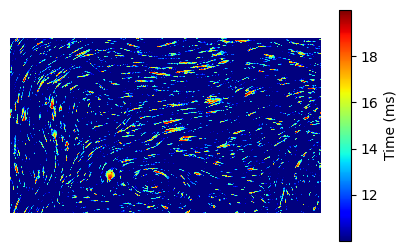

In [3]:
flow_index = 1
flow_names = ["ebiv","water"]

cases = [
    Dict(source_type="real", path="./data/real_old/ebiv_wallflow4_dense.h5"),
    Dict(source_type="evk5", path="./data/n10.hdf5")
]

flow_cbar_cfgs = {
    0: dict(v_min=0.0, v_max=4.0, cbar_ticks=[0.0, 1.0, 2.0, 3.0, 4.0]),
    1: dict(v_min=0.0, v_max=6.0, cbar_ticks=[0.0, 1.5, 3.0, 4.5, 6.0]),
}
flow_cbar_cfg = flow_cbar_cfgs[flow_index]
flow_font_size = 12

event_loader = EventManager(**cases[flow_index])
evts, _ = event_loader.load()
print(evts[:, 2].max()-evts[:, 2].min(), evts[:, 2].min(), evts[:, 2].max())

evts1 = torch.tensor(evts[(evts[:, 2] > 10) & (evts[:, 2] < 20)]).to("cuda")
# evts2 = torch.tensor(evts[(evts[:, 2] > 10) & (evts[:, 2] < 50)]).to("cuda")
print(evts1.shape)
plot_event_time2d(evts1, output_file=None)
torch.cuda.empty_cache()


In [4]:
start = time.time()
cfg = GaussianFlowConfig(H=720, W = 1280, init_n=300, w_div=100, verbose=False, tile_size=80, 
                         w_smooth = 0, cmax_sigma= 0.6, cmax_kernel_size = 5, lr_j=0.005, 
                         enable_jacobian = False, jacobian_mode="full", 
                         iterations=300, residual_block_size=16, 
                         log_scale_min=np.log(3), phase=[50, 200, 250])

results = run_gaussian_flow(events=evts1, cfg=cfg, flowgt=None)

end = time.time()     # 记录结束时间
print(f"运行时间: {end - start:.6f} 秒")
torch.cuda.empty_cache()

运行时间: 4.906598 秒


Figure saved to output/EXP3/ConstGS-water.svg


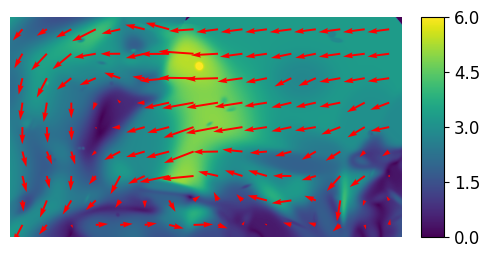

In [ ]:
plot_flow_field(results.flow[0], results.flow[1], output_file=None,
                v_min=flow_cbar_cfg["v_min"], v_max=flow_cbar_cfg["v_max"],
                cbar_ticks=flow_cbar_cfg["cbar_ticks"], 
                colorbar_flag=True, step=1, quiver_step=80, scale=None, 
                slFlag=False, figsize=(5, 3), cbar_tick_size=flow_font_size)

In [5]:
cfg_measure = GaussianFlowConfig(
    H=720, W=1280,
    init_n=300,
    tile_size=80,
    enable_jacobian=True,
    jacobian_mode="full",
)

gs_result, gs_info = measure_gaussian_flow(evts1, cfg_measure)
print_efficiency_info(gs_info)

time=4.770s, learnable_params=225 x 12 = 2700, peak_allocated=2420 MB, peak_reserved=8340 MB


In [11]:
# estimators = [ilk_vg, of_vg, inr_est, inr_vg]
# method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG"]

estimators = [inr_est]
method_names = ["INR_EST"]

def test(events, H=256, W=256):
    for i, m in enumerate(estimators):
        v_h, v_w, div, vor = m(events, H=H, W=W)
        plot_flow_field(v_h, v_w, None, None, output_file=f"./output/EXP3/{method_names[i]}-{flow_names[flow_index]}.svg",
                        magFlag=True, slFlag=False, colorbar_flag=True, step=1, quiver_step=80,
                        v_min=flow_cbar_cfg["v_min"], v_max=flow_cbar_cfg["v_max"],
                        scale=None, figsize=(5, 3), cbar_ticks=flow_cbar_cfg["cbar_ticks"], cbar_tick_size=flow_font_size)
        torch.cuda.empty_cache()

    return 


Figure saved to ./output/EXP3/INR_EST-ebiv.svg


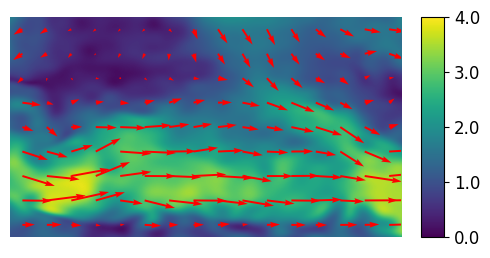

In [12]:
test(evts1, H=720, W=1280)